In [2]:
# check what the scaler expects
import pickle
def extract_au_features(lm_flat):
    pts   = lm_flat.reshape(-1, 3)
    nose  = pts[1].copy()
    pts  -= nose
    scale = np.max(np.abs(pts)) + 1e-6
    pts  /= scale
    p     = pts

    feats = {}
    feats['ear_right']          = np.linalg.norm(p[159] - p[145])
    feats['ear_left']           = np.linalg.norm(p[386] - p[374])
    feats['brow_raise_right']   = p[159][1] - p[52][1]
    feats['brow_raise_left']    = p[386][1] - p[282][1]
    feats['brow_inner_raise']   = (p[159][1] - p[65][1] +
                                   p[386][1] - p[295][1]) / 2
    feats['brow_furrow']        = np.linalg.norm(p[55]  - p[285])
    feats['mar']                = np.linalg.norm(p[13]  - p[14])
    feats['mouth_width']        = np.linalg.norm(p[61]  - p[291])
    feats['lip_corner_right_x'] = p[61][0]
    feats['lip_corner_left_x']  = p[291][0]
    feats['lip_corner_right_y'] = p[61][1]
    feats['lip_corner_left_y']  = p[291][1]
    feats['upper_lip_raise']    = p[0][1]
    feats['nose_width']         = np.linalg.norm(p[98]  - p[327])
    feats['jaw_drop']           = p[152][1]
    feats['eye_squint_right']   = np.linalg.norm(p[33]  - p[133])
    feats['eye_squint_left']    = np.linalg.norm(p[362] - p[263])
    feats['cheek_raise']        = (p[50][1] + p[280][1]) / 2

    au_array = np.array(list(feats.values()))
    return np.concatenate([pts.flatten(), au_array])

with open("scaler.pkl", "rb") as f:
    scaler = pickle.load(f)
print(f"Scaler expects: {scaler.n_features_in_} features")

# check what extract_au_features produces live
import mediapipe as mp
import numpy as np

# dummy landmark flat array (468 landmarks * 3)
dummy = np.zeros(468 * 3, dtype=np.float32)
features = extract_au_features(dummy)
print(f"extract_au_features produces: {len(features)} features")

Scaler expects: 1422 features
extract_au_features produces: 1422 features


In [1]:
import pickle
import xgboost as xgb

# Load it safely once
with open("xgb_model.pkl", "rb") as f:
    pickled_model = pickle.load(f)

# Save natively to a robust JSON or Universal Binary JSON (.ubj) format
pickled_model.save_model("xgb_model.json")
print("Model successfully converted to native JSON format!")

Model successfully converted to native JSON format!


2026-05-20 12:45:16.456593: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-20 12:45:16.459820: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-20 12:45:16.543859: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-05-20 12:45:17.996022: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


Using device: cuda
Loading landmark cache...
Cache size: 14518 entries


Scanning dataset: 100%|██████████| 8/8 [00:00<00:00, 237.60it/s]

Test samples: 14518
Loading model weights...



/tmp/ipykernel_234065/2218857765.py:47: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("nkf_best.pth", map_location=device))
Evaluating: 100


Test accuracy: 0.6568  (65.68%)

Classification Report:
              precision    recall  f1-score   support

     neutral       0.74      0.93      0.82      2368
       happy       0.89      0.93      0.91      2704
       anger       0.58      0.46      0.51      1718
         sad       0.52      0.74      0.61      1584
    surprise       0.49      0.43      0.46      1920
        fear       0.60      0.49      0.54      1664
     disgust       0.59      0.29      0.39      1248
    contempt       0.60      0.66      0.63      1312

    accuracy                           0.66     14518
   macro avg       0.63      0.62      0.61     14518
weighted avg       0.65      0.66      0.64     14518

Saved nkf_pytorch_test_confusion.png


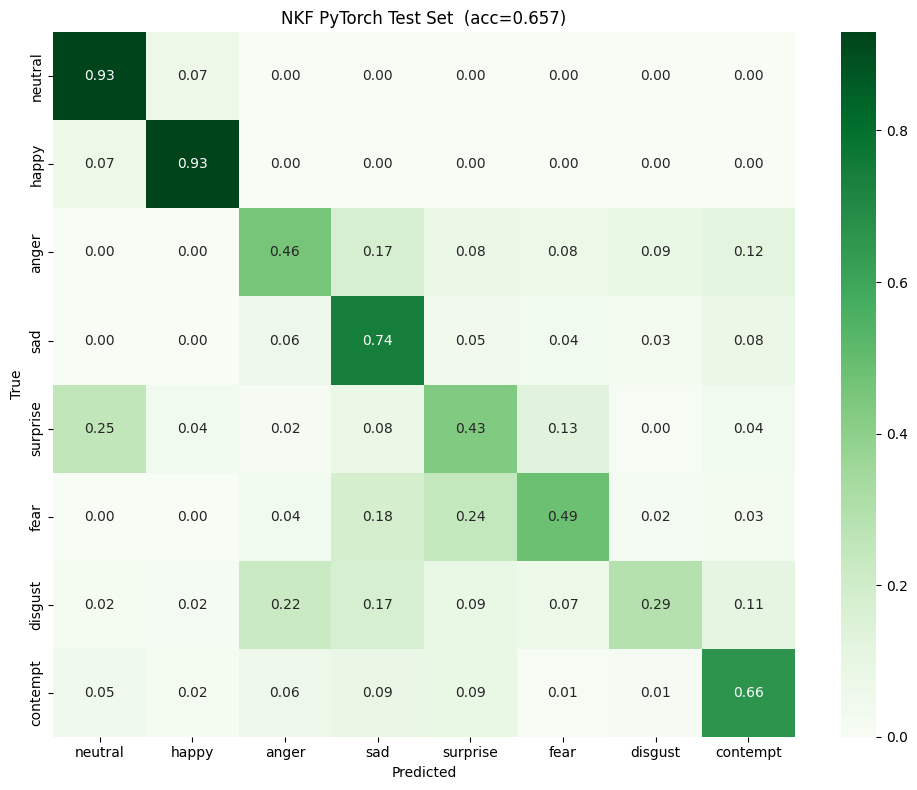

In [1]:
import torch
import torch.nn as nn
import numpy as np
import pickle
import os
from tqdm import tqdm
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# import your classes from training script
from nkf_model import NKF, FERDataset, LABELS

TEST_DIR = "affectnet/Test"

# if __name__ == "__main__":

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

val_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                            std=[0.229, 0.224, 0.225])
])

# --- load landmark cache ---
print("Loading landmark cache...")
with open("landmarks_test.pkl", "rb") as f:
    test_cache = pickle.load(f)
print(f"Cache size: {len(test_cache)} entries")

# --- load dataset ---
test_dataset = FERDataset(TEST_DIR, val_transform,
                            landmark_cache=test_cache)
test_loader  = DataLoader(test_dataset, batch_size=32,
                            shuffle=False, num_workers=0,
                            pin_memory=False)
print(f"Test samples: {len(test_dataset)}")

# --- load model ---
print("Loading model weights...")
model = NKF(pretrained=False).to(device)
model.load_state_dict(torch.load("nkf_best.pth", map_location=device))
model.eval()

# --- evaluate ---
y_pred, y_true = [], []

with torch.no_grad():
    for images, landmarks, labels in tqdm(test_loader, desc="Evaluating"):
        images    = images.to(device)
        landmarks = landmarks.to(device)

        logits = model(images, landmarks)
        preds  = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(preds.tolist())
        y_true.extend(labels.numpy().tolist())

y_pred = np.array(y_pred)
y_true = np.array(y_true)

acc = np.mean(y_pred == y_true)
print(f"\nTest accuracy: {acc:.4f}  ({acc*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=LABELS))

# --- confusion matrix ---
cm = confusion_matrix(y_true, y_pred, normalize='true')
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='.2f',
            xticklabels=LABELS, yticklabels=LABELS,
            cmap='Greens')
plt.title(f'NKF PyTorch Test Set  (acc={acc:.3f})')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig("nkf_pytorch_test_confusion.png")
print("Saved nkf_pytorch_test_confusion.png")

In [ ]:
import torch
import numpy as np
import pickle
import os
from tqdm import tqdm
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
import cv2

# import your classes from training script
from nkf_model import NKF, FERDataset, LABELS

TEST_DIR = "affectnet/Test"

# ---------------------------------------------------------------
# Toggle inference backend here
# ---------------------------------------------------------------
USE_ONNX = True  # set True to use ONNX, False to use PyTorch .pth

PTH_PATH  = "nkf_best.pth"
ONNX_PATH = "nkf_model.onnx"

if __name__ == "__main__":

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    print(f"Backend: {'ONNX' if USE_ONNX else 'PyTorch'}")

    val_transform = transforms.Compose([
        transforms.Resize((96, 96)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    # --- load landmark cache ---
    print("Loading landmark cache...")
    with open("landmarks_test.pkl", "rb") as f:
        test_cache = pickle.load(f)
    print(f"Cache size: {len(test_cache)} entries")

    # --- load dataset ---
    test_dataset = FERDataset(TEST_DIR, val_transform,
                              landmark_cache=test_cache)
    print(f"Test samples: {len(test_dataset)}")

    # ---------------------------------------------------------------
    # Backend A — PyTorch .pth
    # ---------------------------------------------------------------
    if not USE_ONNX:
        test_loader = DataLoader(test_dataset, batch_size=32,
                                 shuffle=False, num_workers=0,
                                 pin_memory=False)

        print(f"Loading PyTorch model from {PTH_PATH}...")
        model = NKF(pretrained=False).to(device)
        model.load_state_dict(torch.load(PTH_PATH, map_location=device,
                                         weights_only=False))
        model.eval()

        y_pred, y_true = [], []
        with torch.no_grad():
            for images, landmarks, labels in tqdm(test_loader, desc="Evaluating"):
                images    = images.to(device)
                landmarks = landmarks.to(device)

                logits = model(images, landmarks)
                preds  = logits.argmax(dim=1).cpu().numpy()

                y_pred.extend(preds.tolist())
                y_true.extend(labels.numpy().tolist())

    # ---------------------------------------------------------------
    # Backend B — ONNX
    # ---------------------------------------------------------------
    else:
        import onnxruntime as ort

        print(f"Loading ONNX model from {ONNX_PATH}...")
        session = ort.InferenceSession(
            ONNX_PATH,
            providers=['CUDAExecutionProvider', 'CPUExecutionProvider']
        )

        y_pred, y_true = [], []

        for i in tqdm(range(len(test_dataset)), desc="Evaluating"):
            img_tensor, lm_tensor, label = test_dataset[i]

            # img_tensor: (3, 96, 96) — already transformed by FERDataset
            img_t = img_tensor.unsqueeze(0).numpy()   # (1, 3, 96, 96)
            lm_t  = lm_tensor.unsqueeze(0).numpy()    # (1, 68, 2)

            logits = session.run(
                ['logits'],
                {'image': img_t, 'landmarks': lm_t}
            )[0]

            y_pred.append(int(np.argmax(logits)))
            y_true.append(label)

    # ---------------------------------------------------------------
    # Results — shared for both backends
    # ---------------------------------------------------------------
    y_pred = np.array(y_pred)
    y_true = np.array(y_true)

    acc = np.mean(y_pred == y_true)
    print(f"\nTest accuracy: {acc:.4f}  ({acc*100:.2f}%)")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=LABELS))

    cm = confusion_matrix(y_true, y_pred, normalize='true')
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='.2f',
                xticklabels=LABELS, yticklabels=LABELS,
                cmap='Greens')
    backend_label = "ONNX" if USE_ONNX else "PyTorch"
    plt.title(f'NKF {backend_label} Test Set  (acc={acc:.3f})')
    plt.ylabel('True')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.savefig(f"nkf_{backend_label.lower()}_test_confusion.png")
    print(f"Saved nkf_{backend_label.lower()}_test_confusion.png")